In [1]:
# DL_6 - Food Image Classification using CNN


In [2]:
import os

path = "Downloads/food-101/food-101/images"

print(os.listdir(path))

['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', 'lobster_roll_sandwich', 'macaroni_and_cheese', 'macarons', 'miso_sou

In [20]:

# 1. Import Libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

from tensorflow import keras


In [21]:

# 2. Load Dataset
train_data = tf.keras.utils.image_dataset_from_directory(
    path,
    image_size=(150, 150),
    batch_size=32
)

class_names = train_data.class_names

print(class_names)

test_data = tf.keras.utils.image_dataset_from_directory(
    path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(150, 150),
    batch_size=32
)


Found 101000 files belonging to 101 classes.
['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheese_plate', 'cheesecake', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', 'lobster_roll_sandwich',

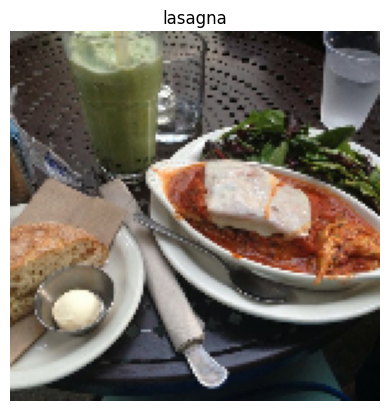

In [ ]:
# 3. Display Original Image
images, labels = next(iter(train_data))

plt.imshow(images[0].numpy().astype("uint8"))
plt.title(class_names[labels[0].numpy()])
plt.axis("off")
plt.show()

In [8]:
# 4. Build CNN Model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(150,150,3)),
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(101, activation='softmax')
])

In [9]:

# 5. Compile Model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [10]:
# 6. Train Model
model.fit(train_data, validation_data=test_data, epochs=5)

Epoch 1/5
3157/3157 ━━━━━━━━━━━━━━━━━━━━ 1269s 401ms/step - accuracy: 0.0844 - loss: 4.1004 - val_accuracy: 0.1718 - val_loss: 3.5639
Epoch 2/5
3157/3157 ━━━━━━━━━━━━━━━━━━━━ 1378s 431ms/step - accuracy: 0.1884 - loss: 3.4581 - val_accuracy: 0.2870 - val_loss: 2.9483
Epoch 3/5
3157/3157 ━━━━━━━━━━━━━━━━━━━━ 8310s 3s/step - accuracy: 0.3019 - loss: 2.8360 - val_accuracy: 0.4355 - val_loss: 2.2476
Epoch 4/5
3157/3157 ━━━━━━━━━━━━━━━━━━━━ 1232s 390ms/step - accuracy: 0.4832 - loss: 2.0100 - val_accuracy: 0.5356 - val_loss: 1.7575
Epoch 5/5
3157/3157 ━━━━━━━━━━━━━━━━━━━━ 1186s 376ms/step - accuracy: 0.6758 - loss: 1.2137 - val_accuracy: 0.5922 - val_loss: 1.5415


In [11]:
# 7. Evaluate Model
loss, accuracy = model.evaluate(test_data)
print("Test Accuracy:", accuracy)

632/632 ━━━━━━━━━━━━━━━━━━━━ 64s 101ms/step - accuracy: 0.5922 - loss: 1.5415
Test Accuracy: 0.592178225517273


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step


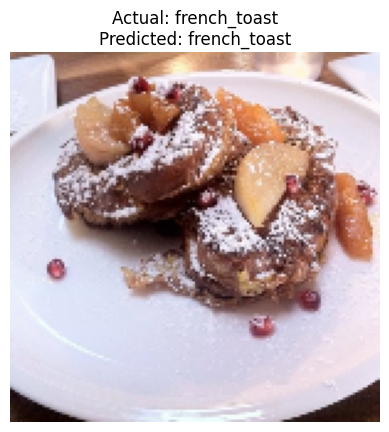

In [12]:

# 8. Actual vs Predicted
images, labels = next(iter(test_data))

prediction = model.predict(images[:1])

actual = class_names[labels[0].numpy()]
predicted = class_names[np.argmax(prediction[0])]

plt.imshow(images[0].numpy().astype("uint8"))
plt.title("Actual: " + actual + "\nPredicted: " + predicted)
plt.axis("off")
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step


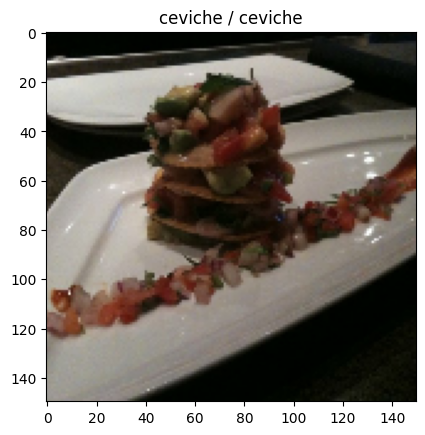

In [14]:
# 8. Actual vs Predicted
x, y = next(iter(test_data))

pred = model.predict(x[:1])

plt.imshow(x[0].numpy().astype("uint8"))
plt.title(class_names[y[0].numpy()] + " / " + class_names[np.argmax(pred[0])])
plt.show()

In [13]:
L_6 – Food Image Classification using CNN
1. What is the aim of this practical? Which dataset is used?

The aim of this practical is to build an image classification model using CNN to identify different food categories. We have used the Food-101 dataset, which contains approximately 101,000 images belonging to 101 food categories, such as pizza, burger, sushi, cake and pasta.

2. What is CNN? Why do we use it?

CNN stands for Convolutional Neural Network. It is a deep learning algorithm mainly used for image processing and classification. We use CNN because it automatically extracts important features such as edges, shapes, colours and patterns from images.

3. What are the different layers used in CNN?

CNN mainly consists of Convolutional, Pooling, Flatten and Dense layers. The Convolutional layer extracts image features, MaxPooling reduces the feature map size, Flatten converts the feature maps into a one-dimensional vector, and Dense layers perform the final classification.

4. What is Conv2D and MaxPooling2D?

Conv2D is used to extract features from images using filters or kernels. MaxPooling2D reduces the dimensions of feature maps while retaining important information. In our model, we have used 32 and 64 filters in the convolutional layers.

5. What is Flatten and Dense layer?

Flatten converts the extracted feature maps into a one-dimensional array. Dense is a fully connected layer that uses these extracted features to classify the food images. We have used 128 neurons in the hidden Dense layer and 101 neurons in the output layer.

6. What are ReLU and Softmax activation functions?

ReLU stands for Rectified Linear Unit. It converts negative values into zero and keeps positive values unchanged. Softmax converts the output values into probabilities for all 101 food categories and helps identify the predicted class.

7. Why do we use Rescaling (1./255)?

Images contain pixel values between 0 and 255. Rescaling converts these values into a range between 0 and 1. This process is called normalization and helps the model learn efficiently.

8. What is batch size, epoch and validation split?

Batch size is the number of images processed together in one training step. We have used a batch size of 32. An epoch represents one complete pass through the training dataset, and we have used 5 epochs. Validation split of 0.2 means 20% of the dataset is reserved for validation and 80% for training.

9. Which optimizer and loss function are used in our model?

We have used the Adam optimizer, which updates model weights to minimize errors during training. We have used Sparse Categorical Crossentropy as our loss function because we have 101 classes and their labels are represented as integer values.

10. What is the difference between training and testing data?

Training data is used to teach the model and learn image patterns, whereas testing data is used to evaluate the model's performance on unseen images.

11. What is image_dataset_from_directory()?

It is a TensorFlow function that loads images directly from folders. It automatically assigns labels according to folder names and resizes images according to the specified dimensions.

12. What is model.fit(), model.evaluate() and model.predict()?

model.fit() is used to train the model, model.evaluate() checks the model's performance and returns loss and accuracy, and model.predict() predicts the food category of a given image.

13. What is argmax()?

Argmax returns the index of the highest value in an array. In our practical, we use it to identify the food category having the highest predicted probability.

14. What is overfitting and underfitting?

Overfitting occurs when a model performs very well on training data but poorly on unseen data. Underfitting occurs when a model fails to learn important patterns even from the training data.

15. What is multiclass classification?

Multiclass classification means classifying data into more than two categories. Our practical is a multiclass classification problem because we classify food images into 101 different categories.

16. What is the difference between classification and detection?

Classification identifies which object or category is present in an image, whereas object detection identifies the object as well as its location using bounding boxes.

17. What is TensorFlow and Keras?

TensorFlow is an open-source deep learning framework developed by Google. Keras is a high-level API used to create, train and evaluate deep learning models easily.

18. What are the applications of food image classification?

Food image classification is used in food recognition applications, calorie estimation, diet monitoring, restaurant automation, food delivery applications and nutritional analysis.

SyntaxError: invalid character '–' (U+2013) (1853051133.py, line 1)